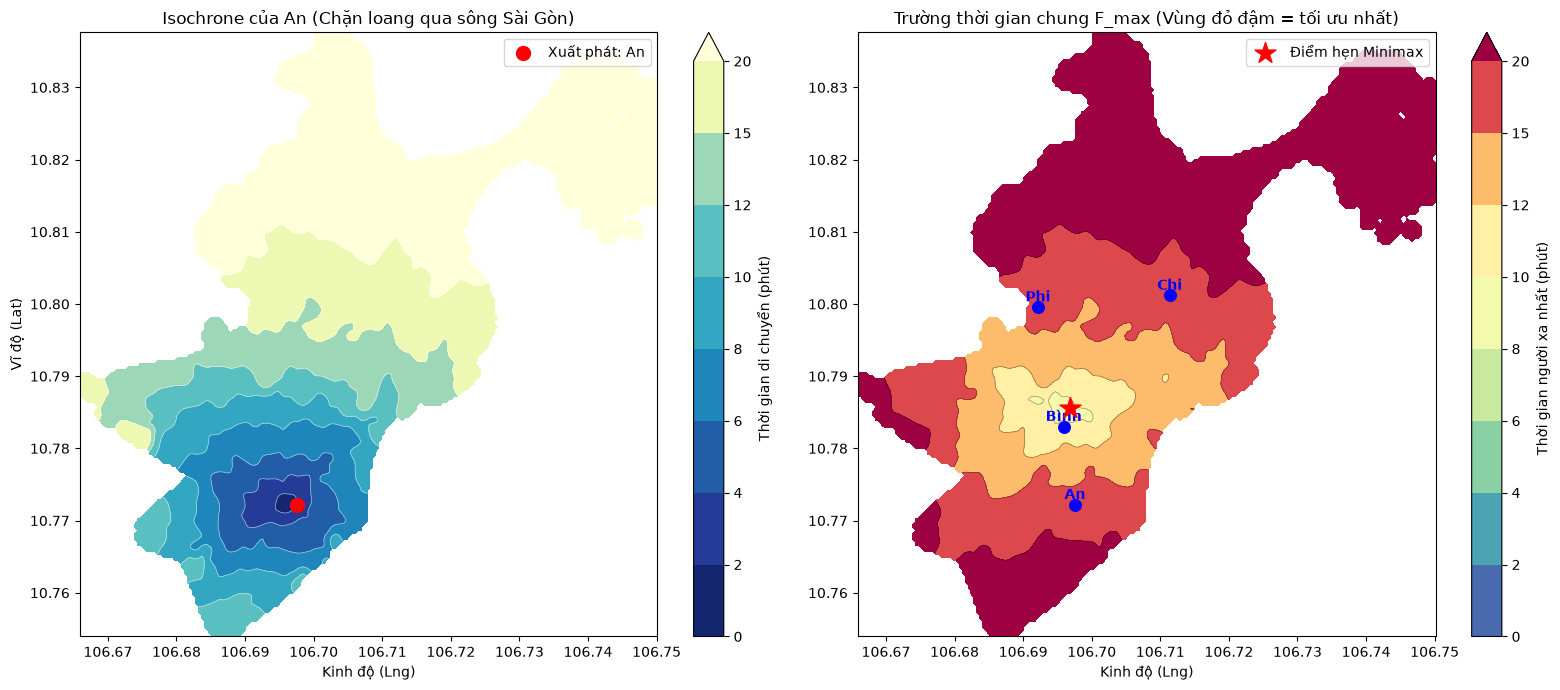

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from scipy.sparse.csgraph import dijkstra as scipy_dijkstra
from scipy.spatial import cKDTree
from scipy.ndimage import gaussian_filter

# 1. Nạp dữ liệu đồ thị & Tính trường thời gian T (phút)
adj_matrix = load_npz("data/hcm_center_moto_adj.npz")
coords = np.load("data/hcm_center_moto_meta.npz")["coords"]  # [lat, lng]
tree = cKDTree(coords)

people_gps = {
    "An": (10.7725, 106.6980),
    "Bình": (10.7827, 106.6959),
    "Chi": (10.8013, 106.7114),
    "Phi": (10.7995, 106.6922),
}
sources = [int(tree.query(gps)[1]) for gps in people_gps.values()]
T = scipy_dijkstra(csgraph=adj_matrix, directed=True, indices=sources) / 60.0
F_max = np.max(T, axis=0)

# 2. Hàm nội suy từ các đỉnh đồ thị ra lưới đều 2D kèm Mask chặn loang qua sông
def create_isochrone_grid(coords, node_values, grid_res=200, max_road_dist_m=180.0):
    lat_min, lat_max = coords[:, 0].min(), coords[:, 0].max()
    lng_min, lng_max = coords[:, 1].min(), coords[:, 1].max()
    
    # Tạo lưới tọa độ đều
    grid_lng = np.linspace(lng_min, lng_max, grid_res)
    grid_lat = np.linspace(lat_min, lat_max, grid_res)
    mesh_lng, mesh_lat = np.meshgrid(grid_lng, grid_lat)
    
    # Tìm đỉnh đường gần nhất cho mỗi ô lưới
    query_points = np.column_stack([mesh_lat.ravel(), mesh_lng.ravel()])
    dists_deg, nearest_idx = tree.query(query_points)
    
    # Đổi khoảng cách độ sang mét xấp xỉ tại vĩ độ 10.78 (~110,500m / độ)
    dists_m = dists_deg * 110500.0
    
    # Gán giá trị thời gian từ đỉnh gần nhất
    grid_vals = node_values[nearest_idx].reshape(grid_res, grid_res)
    mask_water_or_empty = (dists_m > max_road_dist_m).reshape(grid_res, grid_res)
    
    # Làm mượt nhẹ dải màu (chuẩn hóa bỏ qua vùng NaN)
    valid_mask = (~mask_water_or_empty).astype(float)
    filled_vals = np.where(mask_water_or_empty, 0.0, grid_vals)
    smooth_vals = gaussian_filter(filled_vals, sigma=1.2) / np.maximum(gaussian_filter(valid_mask, sigma=1.2), 1e-5)
    
    # Áp lại mask để cắt rỗng vùng sông Sài Gòn và khu không có đường
    smooth_vals[mask_water_or_empty] = np.nan
    return mesh_lng, mesh_lat, smooth_vals

# Tạo lưới cho An (T[0]) và cho điểm hẹn chung (F_max)
mesh_lng, mesh_lat, grid_an = create_isochrone_grid(coords, T[0])
_, _, grid_fmax = create_isochrone_grid(coords, F_max)

# 3. Trực quan hóa dải màu Isochrone
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
levels = [0, 2, 4, 6, 8, 10, 12, 15, 20]

# Bản đồ 1: Vùng loang của riêng An
cf1 = axes[0].contourf(mesh_lng, mesh_lat, grid_an, levels=levels, cmap="YlGnBu_r", extend="max")
axes[0].contour(mesh_lng, mesh_lat, grid_an, levels=levels, colors="white", linewidths=0.5, alpha=0.6)
axes[0].scatter(coords[sources[0], 1], coords[sources[0], 0], c="red", s=100, zorder=5, label="Xuất phát: An")
axes[0].set_title("Isochrone của An (Chặn loang qua sông Sài Gòn)")
axes[0].set_xlabel("Kinh độ (Lng)")
axes[0].set_ylabel("Vĩ độ (Lat)")
axes[0].legend()
plt.colorbar(cf1, ax=axes[0], label="Thời gian di chuyển (phút)")

# Bản đồ 2: Trường thời gian chờ tối đa F_max của cả nhóm
cf2 = axes[1].contourf(mesh_lng, mesh_lat, grid_fmax, levels=levels, cmap="Spectral_r", extend="max")
axes[1].contour(mesh_lng, mesh_lat, grid_fmax, levels=levels, colors="black", linewidths=0.4, alpha=0.5)
for name, idx in zip(people_gps.keys(), sources):
    axes[1].scatter(coords[idx, 1], coords[idx, 0], c="blue", s=70, zorder=5)
    axes[1].text(coords[idx, 1], coords[idx, 0] + 0.0008, name, color="blue", fontweight="bold", ha="center")

best_mm = int(np.argmin(F_max))
axes[1].scatter(coords[best_mm, 1], coords[best_mm, 0], c="red", marker="*", s=250, zorder=6, label="Điểm hẹn Minimax")
axes[1].set_title("Trường thời gian chung F_max (Vùng đỏ đậm = tối ưu nhất)")
axes[1].set_xlabel("Kinh độ (Lng)")
axes[1].legend()
plt.colorbar(cf2, ax=axes[1], label="Thời gian người xa nhất (phút)")

plt.tight_layout()
plt.show()